In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
# grid over parameter plane
n = 501
phi_0 = np.linspace(-1,1,n)
phi_1 = np.linspace(-1, 1, n)
p0, p1 = np.meshgrid(phi_0, phi_1)
p0, p1

(array([[-1.   , -0.996, -0.992, ...,  0.992,  0.996,  1.   ],
        [-1.   , -0.996, -0.992, ...,  0.992,  0.996,  1.   ],
        [-1.   , -0.996, -0.992, ...,  0.992,  0.996,  1.   ],
        ...,
        [-1.   , -0.996, -0.992, ...,  0.992,  0.996,  1.   ],
        [-1.   , -0.996, -0.992, ...,  0.992,  0.996,  1.   ],
        [-1.   , -0.996, -0.992, ...,  0.992,  0.996,  1.   ]],
       shape=(501, 501)),
 array([[-1.   , -1.   , -1.   , ..., -1.   , -1.   , -1.   ],
        [-0.996, -0.996, -0.996, ..., -0.996, -0.996, -0.996],
        [-0.992, -0.992, -0.992, ..., -0.992, -0.992, -0.992],
        ...,
        [ 0.992,  0.992,  0.992, ...,  0.992,  0.992,  0.992],
        [ 0.996,  0.996,  0.996, ...,  0.996,  0.996,  0.996],
        [ 1.   ,  1.   ,  1.   , ...,  1.   ,  1.   ,  1.   ]],
       shape=(501, 501)))

In [7]:
def lp_term(p):
    """L_p regularization term: sum_d |phi_d|^p (p=0 counts non-zero parameters) """
    if p == 0:
        return (p0 != 0).astype(float) + (p1 !=0 ).astype(float)
    return np.abs(p0)**p + np.abs(p1)**p

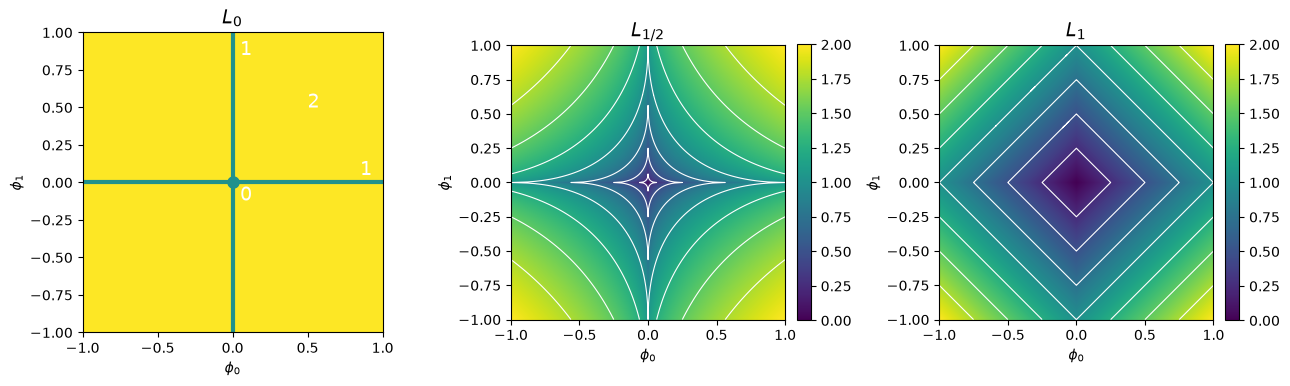

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
titles = [r"$L_0$", r"$L_{1/2}$", r"$L_1$"]
for ax, p, title in zip(axes, [0, 0.5, 1], titles):
    if p == 0:
        ax.set_facecolor(plt.cm.viridis(1.0))
        ax.axvline(0, color=plt.cm.viridis(0.5), lw=3)
        ax.axhline(0, color=plt.cm.viridis(0.5), lw=3)
        ax.plot(0,0, "o", color=plt.cm.viridis(0.5), ms=8)
        ax.text(0.5, 0.5, "2", color="w", fontsize=14)
        ax.text(0.05, 0.85, "1", color="w", fontsize=14)
        ax.text(0.85, 0.05, "1", color="w", fontsize=14)
        ax.text(0.05, -0.12, "0", color="w", fontsize=14)
        ax.set_xlim(-1,1)
        ax.set_ylim(-1,1)

    else:
        Z = lp_term(p)
        im = ax.imshow(Z, extent=[-1,1, -1, 1], origin="lower", cmap="viridis", vmin=0, vmax=2)
        ax.contour(p0, p1, Z, levels=np.arange(0.25, 2.0, 0.25), colors="white", linewidths=0.8)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)


    ax.set_title(title, fontsize=14)
    ax.set_xlabel(r"$\phi_0$")
    ax.set_ylabel(r"$\phi_1$")
    ax.set_aspect("equal")




plt.tight_layout()
plt.savefig("lp_regularization.png", dpi=150)
plt.show()